# Canibalización entre ítems recomendados juntos

La pregunta de este notebook es si un ítem pierde clics cuando se muestra junto a ítems parecidos, y cuánto sesgo le mete eso al IPW por posición. Tiene tres partes.

1. **Open Bandit Dataset.** Se estima la canibalización $\beta$ con los logs de random, se calcula el sesgo que produce en el benchmark de Saito et al. y se descompone el error de los estimadores.
2. **Dataset sintético tipo OBD.** Con canibalización conocida, se compara el IPW por posición con el IPW de vitrina y se calcula el umbral $n^*$. Además, se comprueba que los siete estimadores del benchmark heredan el mismo sesgo. El dataset se construye en dataset_sintetico.ipynb, que hay que correr antes.
3. **KuaiRand-1K.** Se usa la inserción aleatoria de videos para medir la canibalización por saturación con mucha más precisión que en OBD.

# Parte 1. Open Bandit Dataset

Se estima el parámetro de canibalización $\beta$ con los logs de la política random del Open Bandit Dataset. La idea es ver si un ítem pierde clics cuando comparte la vitrina con ítems de su misma categoría. El modelo que planteamos es

$$P(\text{clic en } k) = \theta_k(a_k) - \beta \cdot c_k,$$

donde $c_k$ es cuántos de los otros dos ítems de la vitrina son de la misma categoría que el ítem en la posición $k$. 

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

OBD_PATH = Path("Contenido/Datasets/open_bandit_dataset/open_bandit_dataset")
CAMPAIGN = "men"

In [2]:
UF = [f"user_feature_{i}" for i in range(4)]


def leer_log(politica, campana):
    log = pd.read_csv(OBD_PATH / politica / campana / f"{campana}.csv",
                      usecols=["timestamp", "item_id", "position", "click"] + UF,
                      dtype={c: "category" for c in UF})
    ts = log["timestamp"].str.replace(r"(\d{2}:\d{2}:\d{2})\+", r"\1.000000+", regex=True)
    log["timestamp"] = pd.to_datetime(ts, format="%Y-%m-%d %H:%M:%S.%f%z")
    return log.sort_values("timestamp", kind="stable").reset_index(drop=True)


log = leer_log("random", CAMPAIGN)
pd.DataFrame({"Impresiones": [len(log)], "Timestamps distintos": [log["timestamp"].nunique()],
              "Ítems": [log["item_id"].nunique()], "CTR": [log["click"].mean()]})

,Impresiones,Timestamps distintos,Ítems,CTR
0,452949,439004,34,0.005124


## Reconstrucción de vitrinas

El dataset tiene una fila por impresión y no trae un identificador de vitrina, así que para saber qué ítems se mostraron juntos se agrupan las tres filas de cada vitrina.

Las filas de una misma vitrina no tienen exactamente el mismo timestamp (casi todos son distintos), pero aparecen seguidas, con el mismo usuario y separadas por milisegundos. Entonces se parte una vitrina nueva cuando se cumple alguna de estas condiciones.
- pasan más de $\tau$ segundos desde la fila anterior,
- cambian las características del usuario, o
- se repite una posición.

In [3]:
def reconstruir_vitrinas(log, tau):
    gap = log["timestamp"].diff().dt.total_seconds().fillna(np.inf).to_numpy()
    mismo_usuario = (log[UF] == log[UF].shift()).all(axis=1).to_numpy()
    posiciones = log["position"].to_numpy()

    vitrina = np.empty(len(log), dtype=int)
    actual, vistas = -1, set()
    for i in range(len(log)):
        if gap[i] > tau or not mismo_usuario[i] or posiciones[i] in vistas:
            actual, vistas = actual + 1, set()
        vistas.add(posiciones[i])
        vitrina[i] = actual
    return vitrina


filas = []
for tau in (0.05, 0.1, 0.5):
    tamano = np.bincount(reconstruir_vitrinas(log, tau))
    filas.append({"tau (s)": tau, "Vitrinas": len(tamano),
                  "Con 1 fila": (tamano == 1).sum(), "Con 2 filas": (tamano == 2).sum(),
                  "Con 3 filas": (tamano == 3).sum(),
                  "Impresiones en vitrinas completas": np.mean(np.repeat(tamano, tamano) == 3)})
pd.DataFrame(filas)

,tau (s),Vitrinas,Con 1 fila,Con 2 filas,Con 3 filas,Impresiones en vitrinas completas
0,0.05,154748,4212,2871,147665,0.978024
1,0.10,153398,2633,1979,148786,0.985449
2,0.50,151976,1024,931,150021,0.993628


Con $\tau = 0{,}1$ el 98,5 % de las impresiones queda en vitrinas completas, y el resultado cambia poco con 0,05 o 0,5. Por lo tanto, nos quedamos con $\tau = 0{,}1$ y descartamos las vitrinas incompletas.

In [4]:
log["vitrina"] = reconstruir_vitrinas(log, 0.1)
completas = log[log.groupby("vitrina")["position"].transform("size") == 3].sort_values(["vitrina", "position"])

# una fila por vitrina, con el ítem y el clic de las posiciones 1, 2 y 3
vitrinas = completas["item_id"].to_numpy().reshape(-1, 3)
clics = completas["click"].to_numpy().reshape(-1, 3)
pd.DataFrame(vitrinas[:5], columns=["Posición 1", "Posición 2", "Posición 3"])

,Posición 1,Posición 2,Posición 3
0,0,23,25
1,25,30,17
2,25,30,17
3,25,30,17
4,0,23,25


Antes de estimar, se revisa cómo arma las vitrinas la política random. Cada ítem aparece en cada posición con la misma probabilidad (1/34 en *men*), pero eso no significa que las vitrinas se sorteen de forma uniforme. Para revisarlo, se compara cuántos órdenes distintos aparecen para cada conjunto de tres ítems con lo que se esperaría si el orden fuera al azar.

In [5]:
conjunto = pd.Series([tuple(sorted(v)) for v in vitrinas])
orden = pd.Series([tuple(v) for v in vitrinas])
n_por_conjunto = conjunto.value_counts()
m = log["item_id"].nunique()

pd.Series({
    "Conjuntos de 3 ítems observados": conjunto.nunique(),
    "Conjuntos posibles": m * (m - 1) * (m - 2) // 6,
    "Vitrinas ordenadas distintas": orden.nunique(),
    "Vitrinas ordenadas posibles": m * (m - 1) * (m - 2),
    "Órdenes distintos por conjunto (observado)": orden.groupby(conjunto).nunique().mean(),
    # con n apariciones al azar, cada uno de los 6 órdenes aparece con prob. 1 - (5/6)^n
    "Órdenes distintos por conjunto (si fuera uniforme)": (6 * (1 - (5 / 6) ** n_por_conjunto)).mean(),
}).round(2)

Conjuntos de 3 ítems observados                        5846.00
Conjuntos posibles                                     5984.00
Vitrinas ordenadas distintas                          16813.00
Vitrinas ordenadas posibles                           35904.00
Órdenes distintos por conjunto (observado)                2.88
Órdenes distintos por conjunto (si fuera uniforme)        5.63
dtype: float64

Casi todos los conjuntos de ítems aparecen, pero cada uno se muestra en promedio en 2,9 de sus 6 órdenes posibles, cuando con un orden uniforme serían 5,6. Además, la misma vitrina suele repetirse en impresiones seguidas. Es decir, random no sortea vitrinas de forma uniforme. Esto no impide estimar $\beta$, porque la vitrina se sigue eligiendo sin mirar al usuario, pero como las mismas vitrinas se repiten, los errores estándar se agrupan por conjunto de ítems y no por vitrina.

## Vecinos de la misma categoría

Usamos como categoría de cada ítem la columna item_feature_1 del archivo item_context.csv. Esta columna está anonimizada. Por su estructura probablemente corresponde a la marca, pero usamos "categoría" por simplicidad. Para cada posición contamos cuántos de los otros dos ítems de la vitrina son de su misma categoría.

In [6]:
def contar_vecinos(cat):

    # paso a int antes de sumar 
    igual_12 = (cat[:, 0] == cat[:, 1]).astype(int)
    igual_13 = (cat[:, 0] == cat[:, 2]).astype(int)
    igual_23 = (cat[:, 1] == cat[:, 2]).astype(int)
    return np.column_stack([igual_12 + igual_13, igual_12 + igual_23, igual_13 + igual_23])


item_context = pd.read_csv(OBD_PATH / "random" / CAMPAIGN / "item_context.csv", index_col=0).sort_values("item_id")
categoria = item_context["item_feature_1"].astype("category").cat.codes.to_numpy()
n_items = len(categoria)

vecinos = contar_vecinos(categoria[vitrinas])

pd.DataFrame({"Vecinos de la misma categoría": vecinos.ravel(), "click": clics.ravel()}) \
  .groupby("Vecinos de la misma categoría")["click"].agg(Impresiones="size", CTR="mean")

,Impresiones,CTR
Vecinos de la misma categoría,,
0,329195,0.004970
1,109036,0.004760
2,8127,0.004184


## Estimación de $\beta$

Estimamos una regresión lineal del clic sobre el número de vecinos de la misma categoría, con un efecto fijo por cada combinación ítem × posición.

$$r_{ik} = \alpha_{a_{ik},k} - \beta \cdot c_{ik} + \varepsilon_{ik}.$$

Los efectos fijos capturan qué tan atractivo es cada ítem en cada posición, así que $\beta$ sale de comparar un mismo ítem, en una misma posición, con distintos vecinos. Como en random los vecinos no dependen del usuario, esa comparación es causal.

Para estimar con efectos fijos se le resto a cada variable su promedio dentro de su celda ítem × posición y después hago una regresión simple. 

In [7]:
def estimar_beta(vitrinas, clics, vecinos, grupos, n_items):
    item, pos = vitrinas.ravel(), np.tile(np.arange(3), len(vitrinas))
    r, c = clics.ravel().astype(float), vecinos.ravel().astype(float)

    # le resto a r y a c su promedio 
    celda = item * 3 + pos
    n_celda = np.bincount(celda, minlength=n_items * 3)
    r_dm = r - (np.bincount(celda, r, n_items * 3) / n_celda)[celda]
    c_dm = c - (np.bincount(celda, c, n_items * 3) / n_celda)[celda]
    pendiente = (c_dm * r_dm).sum() / (c_dm ** 2).sum()

    # error estándar por grupos
    residuo = r_dm - pendiente * c_dm
    aporte_grupo = np.bincount(np.repeat(grupos, 3), c_dm * residuo)
    se = np.sqrt((aporte_grupo ** 2).sum()) / (c_dm ** 2).sum()
    return -pendiente, se   # beta es la caída, por eso cambio el signo


# agrupamos los errores por conjunto de ítems
conjunto = pd.Series([tuple(sorted(v)) for v in vitrinas])
grupos = conjunto.astype("category").cat.codes.to_numpy()
beta, se = estimar_beta(vitrinas, clics, vecinos, grupos, n_items)
ctr = clics.mean()

pd.Series({
    "beta": beta,
    "Error estándar": se,
    "IC 95% inferior": beta - 1.96 * se,
    "IC 95% superior": beta + 1.96 * se,
    "z": beta / se,
    "beta / CTR": beta / ctr,
    "Efecto mínimo detectable (80% potencia)": 2.8 * se,
}).round(5)

beta                                       0.00039
Error estándar                             0.00031
IC 95% inferior                           -0.00022
IC 95% superior                            0.00099
z                                          1.24430
beta / CTR                                 0.07866
Efecto mínimo detectable (80% potencia)    0.00087
dtype: float64

Por último, se revisa que el resultado no dependa de la ventana $\tau$. Para esto, y para lo que viene después, se juntan los pasos anteriores en dos funciones, una que, dado un log y su item_context, reconstruye las vitrinas y cuenta los vecinos, y otra que además estima $\beta$.

In [8]:
def vitrinas_campana(log, item_context, tau=0.1):
    categoria = item_context["item_feature_1"].astype("category").cat.codes.to_numpy()
    v = log.assign(vitrina=reconstruir_vitrinas(log, tau))
    v = v[v.groupby("vitrina")["position"].transform("size") == 3].sort_values(["vitrina", "position"])
    vit = v["item_id"].to_numpy().reshape(-1, 3)
    cl = v["click"].to_numpy().reshape(-1, 3)
    vec = contar_vecinos(categoria[vit])
    grp = pd.Series([tuple(sorted(x)) for x in vit]).astype("category").cat.codes.to_numpy()
    return vit, cl, vec, grp, categoria


def beta_campana(log, item_context, tau=0.1):
    vit, cl, vec, grp, categoria = vitrinas_campana(log, item_context, tau)
    b, s = estimar_beta(vit, cl, vec, grp, len(categoria))
    return {"Vitrinas": len(vit), "CTR": cl.mean(), "beta": b, "Error estándar": s}


pd.DataFrame([{"tau (s)": tau, **beta_campana(log, item_context, tau)} for tau in (0.05, 0.1, 0.5)]).round(6)

,tau (s),Vitrinas,CTR,beta,Error estándar
0,0.05,147665,0.004892,0.000363,0.000309
1,0.10,148786,0.004904,0.000386,0.000310
2,0.50,150021,0.004895,0.000382,0.000309


## Resumen de $\beta$

Para las secciones siguientes se guardan el log de *men* y el resultado de $\beta$ con $\tau = 0{,}1$.

In [9]:
logs = {CAMPAIGN: (log, item_context)}   
res = beta_campana(log, item_context)

comparacion = pd.DataFrame([{"Campaña": CAMPAIGN, "Ítems": len(item_context),
                             "Categorías": item_context["item_feature_1"].nunique(),
                             "Impresiones": len(log), **res}]).set_index("Campaña")
comparacion["IC 95% inferior"] = comparacion["beta"] - 1.96 * comparacion["Error estándar"]
comparacion["IC 95% superior"] = comparacion["beta"] + 1.96 * comparacion["Error estándar"]
comparacion["beta / CTR"] = comparacion["beta"] / comparacion["CTR"]
comparacion["Efecto mínimo detectable"] = 2.8 * comparacion["Error estándar"]
comparacion.round(5)

,Ítems,Categorías,Impresiones,Vitrinas,CTR,beta,Error estándar,IC 95% inferior,IC 95% superior,beta / CTR,Efecto mínimo detectable
Campaña,,,,,,,,,,,
men,34,7,452949,148786,0.0049,0.00039,0.00031,-0.00022,0.00099,0.07866,0.00087


## Sesgo por canibalización en el benchmark

En ope.ipynb se estima el CTR de random usando los logs de bts, siguiendo a Saito et al., y se compara con el CTR observado de random. El IPW por posición corrige qué ítem aparece en cada posición, pero en los logs cada ítem aparece con los vecinos que eligió la política que los generó, no con los que elegiría la política evaluada. Si la política evaluada junta más (o menos) ítems de la misma categoría que la de los logs, el IPW por posición tiene un sesgo $\beta\Delta$ ($\beta\Delta/3$ en CTR por impresión, como reporta obp), con

$$\Delta = \sum_k \sum_a \pi_e(a \mid k)\Big(\mathbb{E}_{\pi_e}[c_k \mid a_k = a] - \mathbb{E}_{\pi_b}[c_k \mid a_k = a]\Big).$$

Es decir, para cada ítem en cada posición comparo cuántos vecinos de su categoría tiene con la política evaluada y en los logs, ponderando por qué tan seguido lo muestra la política evaluada. La tabla calcula el sesgo en las dos direcciones. La que corresponde al benchmark es la fila *random* (evaluar random con logs de bts).

In [10]:
def vecinos_por_item(vitrinas, vecinos, n_items):
    veces = np.column_stack([np.bincount(vitrinas[:, k], minlength=n_items) for k in range(3)])
    suma = np.column_stack([np.bincount(vitrinas[:, k], vecinos[:, k], n_items) for k in range(3)])
    return veces, suma / np.maximum(veces, 1)


filas = []
for campana, (log_r, ic_c) in logs.items():
    log_b = leer_log("bts", campana)
    vit_r, _, vec_r, _, categoria = vitrinas_campana(log_r, ic_c)
    vit_b, _, vec_b, _, _ = vitrinas_campana(log_b, ic_c)
    n_items = len(categoria)

    _, vecinos_random = vecinos_por_item(vit_r, vec_r, n_items)
    veces_bts, vecinos_bts = vecinos_por_item(vit_b, vec_b, n_items)
    pi_bts = veces_bts / veces_bts.sum(axis=0)          # pi_bts(a | k)
    pi_random = np.full((n_items, 3), 1 / n_items)       # pi_random(a | k), uniforme como en obp

    b, s = comparacion.loc[campana, "beta"], comparacion.loc[campana, "Error estándar"]
    direcciones = {
        # política evaluada -> (pi_e, vecinos con pi_e, vecinos en los logs usados, CTR real de la evaluada)
        "bts": (pi_bts, vecinos_bts, vecinos_random, log_b["click"].mean()),
        "random": (pi_random, vecinos_random, vecinos_bts, log_r["click"].mean()),
    }
    for evaluada, (pi_e, vecinos_e, vecinos_logs, ctr_real) in direcciones.items():
        con_pi_e = (pi_e * vecinos_e).sum()          # vecinos parecidos por vitrina con la política evaluada
        en_logs = (pi_e * vecinos_logs).sum()        # lo que asume el IPW por posición al usar los logs de la otra
        delta = con_pi_e - en_logs
        sesgos = sorted([(b - 1.96 * s) * delta / 3, (b + 1.96 * s) * delta / 3])
        filas.append({
            "Campaña": campana,
            "Política evaluada": evaluada,
            "Logs usados": "random" if evaluada == "bts" else "bts",
            "Vecinos parecidos (política evaluada)": con_pi_e,
            "Vecinos parecidos (logs usados)": en_logs,
            "Delta": delta,
            "CTR real": ctr_real,
            "Sesgo (CTR por impresión)": b * delta / 3,
            "IC 95% inferior": sesgos[0],
            "IC 95% superior": sesgos[1],
            "Sesgo / CTR real": b * delta / 3 / ctr_real,
        })
    del log_b   # el log de bts es grande, lo libero

sesgo_canibalizacion = pd.DataFrame(filas).set_index(["Campaña", "Política evaluada"])
sesgo_canibalizacion

Logs usados  Vecinos parecidos (política evaluada)  \
Campaña Política evaluada                                                      
men     bts                    random                               0.961987   
        random                    bts                               0.840707   

                           Vecinos parecidos (logs usados)     Delta  \
Campaña Política evaluada                                              
men     bts                                       0.876484  0.085503   
        random                                    0.881012 -0.040305   

                           CTR real  Sesgo (CTR por impresión)  \
Campaña Política evaluada                                        
men     bts                0.006743                   0.000011   
        random             0.005124                  -0.000005   

                           IC 95% inferior  IC 95% superior  Sesgo / CTR real  
Campaña Política evaluada                                                      
men     bts                      -0.000006         0.000028          0.001631  
        random                   -0.000013         0.000003         -0.001011

## Descomposición del error de los estimadores

En ope.ipynb se estima el CTR de random (campaña *men*) con 200 muestras, usando siete estimadores. Con esas 200 estimaciones se puede separar el error de cada estimador. Primero, el error cuadrático medio se divide en sesgo y varianza, como

$$\text{MSE} = \underbrace{\big(\overline{V} - V_{\text{real}}\big)^2}_{\text{sesgo}^2} + \underbrace{\frac{1}{200}\sum_{s}\big(\hat V_s - \overline{V}\big)^2}_{\text{varianza}},$$

donde $\hat V_s$ es la estimación de la semilla $s$, $\overline{V}$ su promedio y $V_{\text{real}}$ el CTR observado de random. Luego, el sesgo se divide en la parte que viene de la canibalización, $\beta\Delta/3$, y el resto, que viene de otras fuentes, como puede ser un modelo de clics mal especificado, errores en los propensity scores de *bts* o cambios entre los periodos de las dos políticas.

El CTR real también tiene ruido, porque es un promedio de 452.949 impresiones. Por eso se reporta el error estándar del sesgo total, que combina la variación entre semillas y el error estándar del CTR real.

In [11]:
ope = pd.read_csv("resultados/ope_men_n10000_tuning_por_semilla.csv")   

log_r = logs["men"][0]
ctr_real = log_r["click"].mean()
se_ctr_real = np.sqrt(ctr_real * (1 - ctr_real) / len(log_r))
canib = sesgo_canibalizacion.loc[("men", "random")]

por_estimador = ope.groupby("estimador")["estimado"]
n_semillas = por_estimador.size()
media = por_estimador.mean()
sesgo = media - ctr_real
varianza = por_estimador.var(ddof=0)
mse = sesgo ** 2 + varianza                    
se_sesgo = np.sqrt(varianza / n_semillas + se_ctr_real ** 2)

descomposicion = pd.DataFrame({
    "CTR estimado (promedio)": media,
    "Sesgo total": sesgo,
    "Error estándar del sesgo": se_sesgo,
    "Varianza": varianza,
    "RMSE x 10^3": np.sqrt(mse) * 1000,
    "% del MSE por sesgo": sesgo ** 2 / mse,
    "% del MSE por varianza": varianza / mse,
    "Sesgo por canibalización": canib["Sesgo (CTR por impresión)"],
    "Sesgo de otras fuentes": sesgo - canib["Sesgo (CTR por impresión)"],
    "Canibalización / sesgo total": canib["Sesgo (CTR por impresión)"] / sesgo,
}).sort_values("RMSE x 10^3")

print(f"CTR real de random: {ctr_real:.5f} (error estándar {se_ctr_real:.5f})")
print(f"Sesgo por canibalización: {canib['Sesgo (CTR por impresión)']:+.2e} "
      f"(IC 95% [{canib['IC 95% inferior']:+.2e}, {canib['IC 95% superior']:+.2e}])")
for col in ["Sesgo total", "Error estándar del sesgo", "Varianza", "Sesgo por canibalización", "Sesgo de otras fuentes"]:
    descomposicion[col] = descomposicion[col].map("{:.2e}".format)
descomposicion.round(4)

CTR real de random: 0.00512 (error estándar 0.00011)
Sesgo por canibalización: -5.18e-06 (IC 95% [-1.33e-05, +2.98e-06])


,CTR estimado (promedio),Sesgo total,Error estándar del sesgo,Varianza,RMSE x 10^3,% del MSE por sesgo,% del MSE por varianza,Sesgo por canibalización,Sesgo de otras fuentes,Canibalización / sesgo total
estimador,,,,,,,,,,
DM,0.0064,1.25e-03,1.23e-04,7.76e-07,1.5308,0.6690,0.3310,-5.18e-06,1.26e-03,-0.0041
DRos,0.0058,6.59e-04,1.75e-04,3.85e-06,2.0707,0.1012,0.8988,-5.18e-06,6.64e-04,-0.0079
Switch-DR,0.0057,5.28e-04,2.09e-04,6.47e-06,2.5976,0.0412,0.9588,-5.18e-06,5.33e-04,-0.0098
IPW,0.0056,4.41e-04,2.10e-04,6.58e-06,2.6023,0.0287,0.9713,-5.18e-06,4.46e-04,-0.0118
SNIPW,0.0055,3.95e-04,2.15e-04,7.00e-06,2.6757,0.0218,0.9782,-5.18e-06,4.00e-04,-0.0131
SNDR,0.0056,4.49e-04,2.15e-04,6.98e-06,2.6801,0.0281,0.9719,-5.18e-06,4.55e-04,-0.0115
DR,0.0052,1.03e-04,3.03e-04,1.61e-05,4.0147,0.0007,0.9993,-5.18e-06,1.08e-04,-0.0504


## Formas no lineales de canibalización

El modelo lineal supone que cada vecino de la misma categoría le quita la misma cantidad de CTR a cualquier ítem, sea muy clickeado o no. Se propone otra forma de cuantificar la canibalización.

**Canibalización multiplicativa.** Cada vecino le quita una fracción del CTR al ítem, no una cantidad fija. El modelo es
$$P(\text{clic en } k) = \theta_k(a_k) \cdot e^{-\gamma c_k}.$$
Así, cada vecino le quita un $1 - e^{-\gamma}$ del CTR al ítem. Como $\theta e^{-\gamma c} \approx \theta - \theta\gamma c$ cuando $\gamma$ es chico, esto es como el modelo lineal pero con un $\beta = \theta\gamma$ distinto para cada ítem, donde los ítems más clickeados pierden más clics.

### Canibalización multiplicativa

Para estimar $\gamma$ se usa una regresión de Poisson con un efecto fijo por celda ítem × posición. Como los clics son muy poco frecuentes, Poisson y logit dan prácticamente lo mismo, y Poisson con efectos fijos es más fácil de resolver. Se hace en dos pasos.

- Para un $\gamma$ dado, el $\theta$ de cada celda que mejor ajusta es la suma de clics de la celda dividida por $\sum e^{-\gamma c}$ en esa celda.
- Con eso, $\gamma$ es el valor donde la derivada de la verosimilitud es cero, es decir, donde $\sum_i c_i\,(r_i - \hat\mu_i) = 0$ con $\hat\mu_i = \hat\theta_{\text{celda}}\, e^{-\gamma c_i}$. Se busca con brentq.

El error estándar también se agrupa por conjunto de ítems.

In [12]:
from scipy.optimize import brentq


def estimar_gamma(vitrinas, clics, vecinos, grupos, n_items):
    item, pos = vitrinas.ravel(), np.tile(np.arange(3), len(vitrinas))
    r, c = clics.ravel().astype(float), vecinos.ravel().astype(float)
    celda = item * 3 + pos
    clics_celda = np.bincount(celda, r, n_items * 3)

    def clics_esperados(gamma):
        # theta de cada celda que mejor ajusta para este gamma
        e = np.exp(-gamma * c)
        theta = clics_celda / np.maximum(np.bincount(celda, e, n_items * 3), 1e-300)
        return theta[celda] * e

    def derivada(gamma):
        return (c * (r - clics_esperados(gamma))).sum()

    if derivada(-3) * derivada(3) > 0:      # no pasa por cero, me quedo con el borde más cercano
        gamma = -3 if abs(derivada(-3)) < abs(derivada(3)) else 3
    else:
        gamma = brentq(derivada, -3, 3)

    # error estándar por grupos
    mu = clics_esperados(gamma)
    c_prom = (np.bincount(celda, mu * c, n_items * 3) / np.maximum(np.bincount(celda, mu, n_items * 3), 1e-300))[celda]
    curvatura = (mu * (c - c_prom) ** 2).sum()
    aporte_grupo = np.bincount(np.repeat(grupos, 3), (r - mu) * (c - c_prom))
    se = np.sqrt((aporte_grupo ** 2).sum()) / curvatura
    return gamma, se


gamma, se_gamma = estimar_gamma(vitrinas, clics, vecinos, grupos, n_items)

pd.Series({
    "gamma": gamma,
    "Error estándar": se_gamma,
    "IC 95% inferior": gamma - 1.96 * se_gamma,
    "IC 95% superior": gamma + 1.96 * se_gamma,
    "z": gamma / se_gamma,
    "CTR que quita cada vecino (1 - e^-gamma)": 1 - np.exp(-gamma),
}).round(4)

gamma                                       0.0797
Error estándar                              0.0654
IC 95% inferior                            -0.0485
IC 95% superior                             0.2079
z                                           1.2183
CTR que quita cada vecino (1 - e^-gamma)    0.0766
dtype: float64

Para comparar las dos formas, se expresa cada una como la fracción del CTR que se pierde por tener uno o dos vecinos de la misma categoría.

In [13]:
comparacion_formas = pd.DataFrame({
    "Pérdida con 1 vecino (% del CTR)": [beta / ctr, 1 - np.exp(-gamma)],
    "Pérdida con 2 vecinos (% del CTR)": [2 * beta / ctr, 1 - np.exp(-2 * gamma)],
    "Error estándar (1 vecino)": [se / ctr, np.exp(-gamma) * se_gamma],
}, index=["Lineal", "Multiplicativa"])
(comparacion_formas * 100).round(2)

,Pérdida con 1 vecino (% del CTR),Pérdida con 2 vecinos (% del CTR),Error estándar (1 vecino)
Lineal,7.87,15.73,6.32
Multiplicativa,7.66,14.73,6.04


Las dos formas dicen lo mismo. Un vecino de la misma categoría le quitaría cerca de un 7–8 % del CTR al ítem, pero ninguna estimación es significativa. Con un CTR de 0,5 % la forma lineal y la multiplicativa son casi iguales ($\theta e^{-\gamma c} \approx \theta - \theta\gamma c$), así que con estos datos no se puede distinguir cuál es la correcta. Por eso, para lo que sigue se mantiene el modelo lineal.

# Parte 2. Dataset sintético tipo OBD

Con los datos reales de OBD hay tres cosas que no se pueden hacer, que son conocer el $\beta$ verdadero, calcular el IPW de vitrina (porque random no sortea las vitrinas de forma uniforme y no conocemos la probabilidad de cada vitrina) y tener muestras tan grandes como queramos. Por eso se usa un dataset sintético que copia la estructura de OBD (campaña *men*), pero donde todo eso es conocido. El dataset se construye en dataset_sintetico.ipynb (hay que correrlo antes), y aquí solo se carga.

**Ítems y clics.** Se usan los mismos 34 ítems con sus 7 categorías. Hay 20 tipos de usuario, cada uno con 5 características $x$, y cada ítem tiene un vector $v_a$ de 5 componentes. La probabilidad de clic sin canibalización es
$$\theta_k(x, a) = \text{CTR}_a \cdot \text{efecto}_k \cdot e^{\sigma \langle x, v_a\rangle/\sqrt{5} - \sigma^2/2},$$
donde $\text{CTR}_a$ es el CTR del ítem en random y $\text{efecto}_k$ es el efecto de la posición, ambos sacados de OBD. El último factor hace que a cada tipo de usuario le gusten más unos ítems que otros, con $\sigma = 0{,}25$, y vale 1 en promedio. Los clics se generan con el modelo lineal
$$P(\text{clic en } k) = \theta_k(x, a_k) - \beta c_k, \qquad \beta = s \cdot \text{CTR}.$$
Se prueba con $s$ igual a 0, a 0,05, a 0,10 y a 0,15. El $\beta$ estimado en OBD es cerca de 0,08 veces el CTR, así que ese rango lo cubre. No se usa un $s$ más grande porque el $\theta$ más bajo es 0,33 veces el CTR, y con dos vecinos la probabilidad quedaría negativa.

**Política de los logs.** Random, pero esta vez uniforme de verdad, es decir, las 35.904 vitrinas ordenadas posibles tienen la misma probabilidad. Así se conoce la probabilidad de cada vitrina y se puede usar el IPW de vitrina.

**Políticas evaluadas.** Eligen la vitrina posición por posición, entre los ítems que quedan, con probabilidad proporcional a
$$\exp\big(\eta \log \theta_1(x, a) + \kappa \cdot \#\{\text{ítems ya elegidos de la misma categoría que } a\}\big).$$
- *populares*, con $\eta = 3$ y $\kappa = 0$. Muestra más los ítems que le gustan al usuario. Tiene 0,98 vecinos de la misma categoría por vitrina, parecido a bts en OBD (0,96).
- *parecidos*, con $\eta = 3$ y $\kappa = 1{,}5$. Además junta ítems de la misma categoría, con 2,63 vecinos por vitrina.

En los logs uniformes hay 0,83 vecinos por vitrina.

In [14]:
# dataset construido en dataset_sintetico.ipynb
datos = np.load("Contenido/Datasets/dataset_sintetico.npz")
theta_sint, todas, vecinos_todas = datos["theta"], datos["todas"], datos["vecinos_todas"]
ctr_sint = float(datos["ctr"])         # CTR de referencia para beta = s * CTR
N_TIPOS = theta_sint.shape[0]
K = np.arange(3)
politicas_sint = {nombre: (datos[f"prob_{nombre}"], datos[f"pi_e_{nombre}"], datos[f"vec_e_{nombre}"])
                  for nombre in datos["politicas"]}

pd.DataFrame({
    "random uniforme (logs)": {"Vecinos de la misma categoría por vitrina": vecinos_todas.sum(axis=1).mean()},
    **{nombre: {"Vecinos de la misma categoría por vitrina": (prob @ vecinos_todas.sum(axis=1)).mean()}
       for nombre, (prob, _, _) in politicas_sint.items()},
}).round(3)

,random uniforme (logs),populares,parecidos
Vecinos de la misma categoría por vitrina,0.834,0.982,2.625


## Sesgo, varianza y umbral $n^*$

Como todas las vitrinas posibles son conocidas, todo se calcula de forma exacta. Para cada política y cada $s$ se calcula lo siguiente.

- el CTR real de la política evaluada,
- el sesgo del IPW por posición, para comparar con $\beta\Delta/3$ de la Proposición 1,
- la desviación estándar de una vitrina para el IPW por posición ($\sigma_{\text{pos}}$) y para el IPW de vitrina ($\sigma_{\text{vit}}$).

Con $n$ vitrinas, el IPW por posición tiene $\text{MSE}_{\text{pos}}(n) = \text{sesgo}^2 + \sigma^2_{\text{pos}}/n$ y el IPW de vitrina, que es insesgado, tiene $\text{MSE}_{\text{vit}}(n) = \sigma^2_{\text{vit}}/n$. El umbral donde se cruzan es
$$n^* = \frac{\sigma^2_{\text{vit}} - \sigma^2_{\text{pos}}}{\text{sesgo}^2}.$$
Con menos de $n^*$ vitrinas conviene el IPW por posición aunque tenga sesgo, porque tiene mucha menos varianza. Con más de $n^*$ conviene el de vitrina.

Todo está en CTR por impresión, como en obp, y $n$ se cuenta en vitrinas (cada vitrina son 3 filas en obp).

In [15]:
S_SINT = (0, 0.05, 0.10, 0.15)
P_LOGS_VIT = 1 / len(todas)       # probabilidad de cada vitrina en los logs
P_LOGS_POS = 1 / n_items          # probabilidad de cada ítem en cada posición en los logs

# vecinos esperados de cada ítem en cada posición con los logs uniformes
vecinos_logs_sint = np.column_stack([np.bincount(todas[:, k], vecinos_todas[:, k], n_items)
                                     / np.bincount(todas[:, k], minlength=n_items) for k in range(3)])

filas = []
for nombre, (prob, pi_e, vec_e) in politicas_sint.items():
    delta = (pi_e * (vec_e - vecinos_logs_sint[None])).sum(axis=(1, 2)).mean()   # promedio sobre tipos de usuario
    for s in S_SINT:
        b = s * ctr_sint
        valor, media_pos, m2_pos, m2_vit = 0, 0, 0, 0
        for u in range(N_TIPOS):
            p = theta_sint[u][todas, K] - b * vecinos_todas          # prob. de clic en cada posición de cada vitrina
            valor += (prob[u][:, None] * p).sum() / 3 / N_TIPOS
            # IPW por posición = (1/3) sum_k w_k r_k, con clics independientes dada la vitrina
            w = pi_e[u][todas, K] / P_LOGS_POS
            suma = (w * p).sum(axis=1)
            media_pos += suma.mean() / 3 / N_TIPOS
            m2_pos += ((w ** 2 * p).sum(axis=1) + suma ** 2 - (w ** 2 * p ** 2).sum(axis=1)).mean() / 9 / N_TIPOS
            # IPW de vitrina = W (1/3) sum_k r_k
            W = prob[u] / P_LOGS_VIT
            m2_vit += (W ** 2 * (p.sum(axis=1) + p.sum(axis=1) ** 2 - (p ** 2).sum(axis=1))).mean() / 9 / N_TIPOS
        sesgo = media_pos - valor
        var_pos, var_vit = m2_pos - media_pos ** 2, m2_vit - valor ** 2
        filas.append({"Política evaluada": nombre, "s": s, "beta": b, "Delta": delta, "CTR real": valor,
                      "Sesgo IPW por posición": sesgo, "beta Delta / 3": b * delta / 3,
                      "sigma pos": np.sqrt(var_pos), "sigma vitrina": np.sqrt(var_vit),
                      "n*": (var_vit - var_pos) / sesgo ** 2 if s > 0 else np.inf})

exacto_sint = pd.DataFrame(filas).set_index(["Política evaluada", "s"])
tabla = exacto_sint.copy()
tabla["Sesgo / CTR real (%)"] = tabla["Sesgo IPW por posición"] / tabla["CTR real"] * 100
for col in ["beta", "CTR real", "Sesgo IPW por posición", "beta Delta / 3"]:
    tabla[col] = tabla[col].map("{:.2e}".format)
tabla["n*"] = tabla["n*"].map(lambda v: "infinito" if np.isinf(v) else f"{v:,.0f}")
tabla.round(3)

beta  Delta  CTR real Sesgo IPW por posición  \
Política evaluada s                                                        
populares         0.00  0.00e+00  0.124  7.27e-03               0.00e+00   
                  0.05  2.56e-04  0.124  7.18e-03               1.06e-05   
                  0.10  5.12e-04  0.124  7.10e-03               2.12e-05   
                  0.15  7.69e-04  0.124  7.01e-03               3.19e-05   
parecidos         0.00  0.00e+00  1.721  7.22e-03               0.00e+00   
                  0.05  2.56e-04  1.721  7.00e-03               1.47e-04   
                  0.10  5.12e-04  1.721  6.77e-03               2.94e-04   
                  0.15  7.69e-04  1.721  6.55e-03               4.41e-04   

                       beta Delta / 3  sigma pos  sigma vitrina           n*  \
Política evaluada s                                                            
populares         0.00       0.00e+00      0.088          0.226     infinito   
                  0.05       1.06e-05      0.088          0.225  380,072,337   
                  0.10       2.12e-05      0.087          0.223   93,732,476   
                  0.15       3.19e-05      0.087          0.222   41,087,935   
parecidos         0.00       0.00e+00      0.088          0.404     infinito   
                  0.05       1.47e-04      0.088          0.396    6,915,816   
                  0.10       2.94e-04      0.087          0.388    1,656,391   
                  0.15       4.41e-04      0.087          0.380      703,978   

                        Sesgo / CTR real (%)  
Política evaluada s                           
populares         0.00                 0.000  
                  0.05                 0.148  
                  0.10                 0.299  
                  0.15                 0.454  
parecidos         0.00                 0.000  
                  0.05                 2.101  
                  0.10                 4.341  
                  0.15                 6.734

- El sesgo del IPW por posición es exactamente $\beta\Delta/3$, igual que en la Proposición 1.
- Para *populares* el sesgo es muy chico (bajo 0,5 % del CTR con $s = 0{,}15$), porque $\Delta = 0{,}12$, es decir, muestra casi la misma cantidad de ítems parecidos que los logs. Para *parecidos*, $\Delta = 1{,}72$ y el sesgo llega a 6,7 % del CTR.
- El IPW de vitrina tiene entre 2,6 y 4,6 veces la desviación estándar del IPW por posición. Por eso $n^*$ es enorme. Para *populares* hacen falta más de 40 millones de vitrinas (120 millones de filas) para que convenga el IPW de vitrina, y para *parecidos* entre 0,7 y 6,9 millones de vitrinas (de 2,1 a 20,7 millones de filas) según $s$. Como referencia, el log de bts en *men* tiene 1,3 millones de vitrinas (unos 4 millones de filas) y el benchmark usa 10.000 filas.

## Comprobación con muestras

Se simulan 200 logs para cada combinación de política, $s$ y $n$ (334, 3.334 y 33.334 vitrinas, es decir, unas 1.000, 10.000 y 100.000 filas, para que el tamaño del medio coincida con el $n$ = 10.000 del benchmark). En cada log se sortea un tipo de usuario y una vitrina uniforme para cada fila, se generan los clics y se calculan tres estimadores.

- IPW por posición, $w_k r_k$, con $w_k = \pi_e(a_k \mid x, k)/\pi_b(a_k \mid k)$.
- IPW de vitrina, $W \cdot \frac{1}{3}\sum_k r_k$, con $W = \pi_e(\text{vitrina} \mid x)/\pi_b(\text{vitrina})$.
- IPW por posición corregido, $w_k\big(r_k + \hat\beta\,(c_k - \mathbb{E}_{\pi_e}[c_k \mid a_k, x])\big)$, con $\hat\beta$ estimado en el mismo log con estimar_beta. Le devuelve a cada clic lo que le quitaron sus vecinos en los logs y le resta lo que le quitarían con $\pi_e$, así que es insesgado.


In [16]:
def simular_log_sint(nombre, s, n, semilla):
    prob, pi_e, vec_e = politicas_sint[nombre]
    rng = np.random.default_rng(semilla)
    u = rng.integers(N_TIPOS, size=n)                       # tipo de usuario de cada fila
    idx = rng.integers(len(todas), size=n)                  # vitrina uniforme
    vit, vec = todas[idx], vecinos_todas[idx]
    r = (rng.random((n, 3)) < theta_sint[u[:, None], vit, K] - s * ctr_sint * vec).astype(float)
    return u, idx, vit, vec, r


def estimadores_sint(nombre, u, idx, vit, vec, r):
    prob, pi_e, vec_e = politicas_sint[nombre]
    w = pi_e[u[:, None], vit, K] / P_LOGS_POS
    W = prob[u, idx] / P_LOGS_VIT
    b, _ = estimar_beta(vit, r, vec, np.arange(len(vit)), n_items)
    return {"IPW por posición": (w * r).mean(),
            "IPW de vitrina": (W * r.mean(axis=1)).mean(),
            "IPW por posición corregido": (w * (r + b * (vec - vec_e[u[:, None], vit, K]))).mean()}


filas = []
for nombre in politicas_sint:
    for s in S_SINT:
        for n in (334, 3_334, 33_334):
            for semilla in range(200):
                est = estimadores_sint(nombre, *simular_log_sint(nombre, s, n, semilla))
                filas += [{"Política evaluada": nombre, "s": s, "n": n, "semilla": semilla, "Estimador": e, "Estimado": v}
                          for e, v in est.items()]

sim_sint = pd.DataFrame(filas)
sim_sint["CTR real"] = sim_sint.set_index(["Política evaluada", "s"]).index.map(exacto_sint["CTR real"])
sim_sint["error2"] = (sim_sint["Estimado"] - sim_sint["CTR real"]) ** 2
sim_sint.to_csv("resultados/sintetico_canibalizacion.csv", index=False)

g = sim_sint.groupby(["Política evaluada", "s", "n", "Estimador"])
resumen_sim = pd.DataFrame({
    "Sesgo (% CTR)": (g["Estimado"].mean() - g["CTR real"].first()) / g["CTR real"].first() * 100,
    "RMSE (% CTR)": np.sqrt(g["error2"].mean()) / g["CTR real"].first() * 100,
})
resumen_sim.unstack("Estimador").round(2)

/var/folders/6b/vms2nd3d2973khdvtj0gmh7c0000gn/T/ipykernel_8373/1913342958.py:8: RuntimeWarning: invalid value encountered in divide
  r_dm = r - (np.bincount(celda, r, n_items * 3) / n_celda)[celda]
/var/folders/6b/vms2nd3d2973khdvtj0gmh7c0000gn/T/ipykernel_8373/1913342958.py:9: RuntimeWarning: invalid value encountered in divide
  c_dm = c - (np.bincount(celda, c, n_items * 3) / n_celda)[celda]


Sesgo (% CTR)                   \
Estimador                    IPW de vitrina IPW por posición   
Política evaluada s    n                                       
parecidos         0.00 334            23.56           -10.23   
                       3334           -6.94             3.57   
                       33334           3.81            -0.09   
                  0.05 334            24.36            -8.10   
                       3334           -6.59             5.73   
                       33334           3.97             1.97   
                  0.10 334            28.23            -5.70   
                       3334           -6.88             8.11   
                       33334           3.62             4.15   
                  0.15 334            30.50            -4.34   
                       3334           -6.35            10.47   
                       33334           3.73             6.46   
populares         0.00 334            -2.46           -10.18   
                       3334            1.10             3.41   
                       33334           1.07            -0.09   
                  0.05 334            -4.29            -9.99   
                       3334            0.77             3.56   
                       33334           1.22             0.04   
                  0.10 334            -3.38            -9.50   
                       3334            0.88             3.80   
                       33334           1.09             0.16   
                  0.15 334            -3.48           -10.28   
                       3334            0.92             3.86   
                       33334           1.16             0.24   

                                                          RMSE (% CTR)  \
Estimador                    IPW por posición corregido IPW de vitrina   
Política evaluada s    n                                                 
parecidos         0.00 334                        -7.61         445.55   
                       3334                        3.76          64.97   
                       33334                       0.42          32.35   
                  0.05 334                        -6.97         458.83   
                       3334                        3.90          66.23   
                       33334                       0.34          33.02   
                  0.10 334                        -5.94         474.23   
                       3334                        3.99          66.57   
                       33334                       0.26          33.59   
                  0.15 334                        -6.77         490.64   
                       3334                        3.71          68.21   
                       33334                       0.08          34.78   
populares         0.00 334                       -10.11         196.32   
                       3334                        3.44          53.02   
                       33334                      -0.05          18.89   
                  0.05 334                       -10.01         195.79   
                       3334                        3.45          53.75   
                       33334                      -0.07          19.04   
                  0.10 334                        -9.63         198.16   
                       3334                        3.53          53.62   
                       33334                      -0.11          19.14   
                  0.15 334                       -10.56         200.62   
                       3334                        3.42          53.95   
                       33334                      -0.20          19.54   

                                                                          
Estimador                    IPW por posición IPW por posición corregido  
Política evaluada s    n                                                  
parecidos         0.00 334              60.32                      78.72  
  

- Para *populares*, corregir no cambia nada, porque el sesgo por canibalización es tan chico que los dos estimadores dan casi lo mismo.
- Para *parecidos*, con 33.334 vitrinas (unas 100.000 filas) el IPW por posición tiene un sesgo de 2 a 6,5 % del CTR según $s$. Corregir lo deja bajo 0,5 % y baja el RMSE de 8,5 % a 8,3 % con $s = 0{,}10$, y de 10,1 % a 8,5 % con $s = 0{,}15$. Con 3.334 vitrinas (unas 10.000 filas, como el benchmark) corregir casi no cambia el RMSE, y cuando no hay canibalización ($s = 0$) lo empeora un poco (de 24,7 % a 27,1 %), porque se agrega el error de $\hat\beta$ sin ganar nada.
- Con 334 vitrinas (unas 1.000 filas) todos los estimadores son muy ruidosos, con un RMSE sobre 60 % del CTR.
- El IPW de vitrina tiene entre 2,2 y 7,5 veces el RMSE del IPW por posición. Además aparece con sesgos grandes en las muestras chicas (entre −7 % y 31 %). Esto no necesariamente indica que sea un sesgo real. Sus pesos son tan dispersos que en la mayoría de los logs se equivoca poco y de vez en cuando se equivoca muchísimo, y con 200 simulaciones esos casos raros no alcanzan a compensarse. Con 33.334 vitrinas eso se reduce.

El gráfico muestra el RMSE según $n$ para $s = 0{,}10$. Las líneas son las curvas exactas de la tabla anterior y los puntos son las simulaciones.

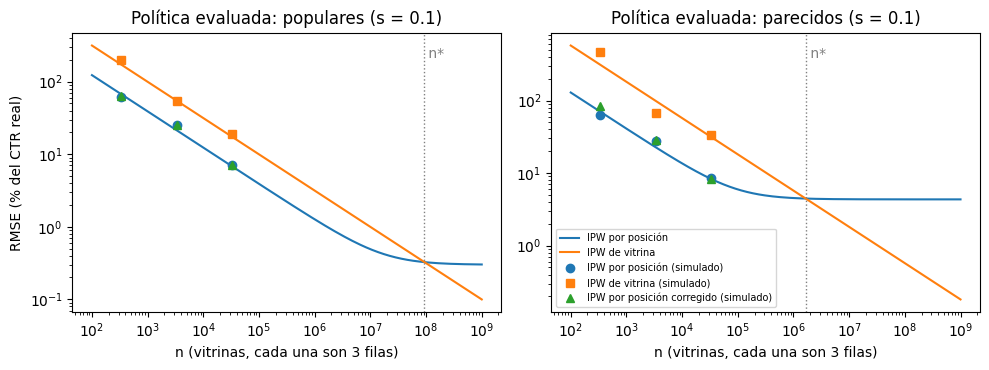

In [17]:
import matplotlib.pyplot as plt

S_GRAF = 0.10
n_grilla = np.logspace(2, 9, 200)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
for eje, nombre in zip(ejes, politicas_sint):
    fila = exacto_sint.loc[(nombre, S_GRAF)]
    v = fila["CTR real"]
    eje.plot(n_grilla, np.sqrt(fila["Sesgo IPW por posición"] ** 2 + fila["sigma pos"] ** 2 / n_grilla) / v * 100,
             color="tab:blue", label="IPW por posición")
    eje.plot(n_grilla, fila["sigma vitrina"] / np.sqrt(n_grilla) / v * 100, color="tab:orange", label="IPW de vitrina")
    eje.axvline(fila["n*"], color="gray", ls=":", lw=1)
    eje.text(fila["n*"], 0.95, " n*", color="gray", va="top", transform=eje.get_xaxis_transform())
    for est, color, marca in (("IPW por posición", "tab:blue", "o"), ("IPW de vitrina", "tab:orange", "s"),
                              ("IPW por posición corregido", "tab:green", "^")):
        t = resumen_sim.loc[(nombre, S_GRAF)].xs(est, level="Estimador")
        eje.plot(t.index, t["RMSE (% CTR)"], marca, color=color, label=f"{est} (simulado)")
    eje.set_xscale("log")
    eje.set_yscale("log")
    eje.set_title(f"Política evaluada: {nombre} (s = {S_GRAF})")
    eje.set_xlabel("n (vitrinas, cada una son 3 filas)")
ejes[0].set_ylabel("RMSE (% del CTR real)")
ejes[1].legend(fontsize=7)
fig.tight_layout()
fig.savefig("resultados/fig_sintetico_rmse_n.png", dpi=200)
plt.show()

Las simulaciones del IPW por posición calzan con la curva exacta. Las del IPW de vitrina se alejan de su curva con $n$ chico (quedan por encima con 334 vitrinas y por debajo con 3.334), porque con pesos tan dispersos 200 simulaciones no alcanzan para medir bien su error. Con 33.334 vitrinas ya calzan. En *parecidos* las curvas se cruzan cerca de 1,7 millones de vitrinas (unos 5 millones de filas). En *populares* se cruzan recién en casi 100 millones de vitrinas, así que en la práctica el IPW por posición siempre conviene. El IPW por posición corregido sigue al IPW por posición sin corregir cuando $n$ es chico, y no se queda pegado en el sesgo cuando $n$ crece.

## Los estimadores del benchmark con canibalización

Hasta aquí solo se evaluaron variantes de IPW. Pero los siete estimadores que se compararon en OBD, KuaiRand y KuaiRec (IPW, SNIPW, DM, DR, SNDR, Switch-DR y DRos) suponen lo mismo que el IPW por posición, que el clic en una posición depende solo del ítem que está ahí. En DM y DR, el modelo de clics $\hat q$ ve el contexto y el ítem, pero no a los vecinos. Por eso, si hay canibalización, todos deberían heredar un sesgo parecido a $\beta\Delta/3$.

Para comprobarlo se corren los siete estimadores de obp, con los mismos hiperparámetros que en ope.ipynb, sobre logs del dataset sintético, con estas combinaciones.
- políticas *populares* y *parecidos*,
- $s = 0$ (sin canibalización) y $s = 0{,}15$,
- 100 logs de 3.334 vitrinas cada uno, es decir, 10.002 filas en formato obp, el mismo tamaño que el $n$ = 10.000 del benchmark.

Se usan las mismas semillas con $s = 0$ y $s = 0{,}15$, así que los dos logs tienen los mismos usuarios y vitrinas y solo cambian los clics. Entonces, la diferencia de sesgo entre los dos escenarios, semilla por semilla, es lo que agrega la canibalización. También se incluye el IPW por posición corregido.

Los resultados se guardan en resultados/sintetico_estimadores_obp.csv. Si ese archivo ya existe se carga, y si no, se recalcula (demora cerca de 30 minutos).

In [18]:
import warnings
from sklearn.ensemble import HistGradientBoostingClassifier
from obp.ope import (OffPolicyEvaluation, RegressionModel, DirectMethod, InverseProbabilityWeighting,
                     SelfNormalizedInverseProbabilityWeighting, DoublyRobust, SelfNormalizedDoublyRobust,
                     SwitchDoublyRobustTuning, DoublyRobustWithShrinkageTuning)

x_tipo = datos["x_tipo"]
LAMBDAS = [1, 5, 10, 50, 100, 500, 1000, 5000, 10000]
TUNING = dict(lambdas=LAMBDAS, tuning_method="mse", delta=0.05)


def crear_estimadores():
    # los mismos siete estimadores de ope.ipynb
    return [InverseProbabilityWeighting(estimator_name="IPW"),
            SelfNormalizedInverseProbabilityWeighting(estimator_name="SNIPW"),
            DirectMethod(estimator_name="DM"),
            DoublyRobust(estimator_name="DR"),
            SelfNormalizedDoublyRobust(estimator_name="SNDR"),
            SwitchDoublyRobustTuning(**TUNING, estimator_name="Switch-DR"),
            DoublyRobustWithShrinkageTuning(**TUNING, estimator_name="DRos")]


def estimadores_obp(nombre, s, n, semilla):
    prob, pi_e, vec_e = politicas_sint[nombre]
    u, idx, vit, vec, r = simular_log_sint(nombre, s, n, semilla)
    u_fila = np.repeat(u, 3)
    feedback = {"n_rounds": 3 * n, "n_actions": n_items, "context": x_tipo[u_fila], "action_context": np.eye(n_items),
                "action": vit.ravel(), "position": np.tile(K, n), "reward": r.ravel().astype(int),
                "pscore": np.full(3 * n, P_LOGS_POS)}
    modelo_q = RegressionModel(n_actions=n_items, len_list=3, fitting_method="normal",
                               action_context=feedback["action_context"],
                               base_model=HistGradientBoostingClassifier(learning_rate=0.01, max_iter=100, max_depth=5,
                                                                         min_samples_leaf=10, random_state=semilla))
    q_hat = modelo_q.fit_predict(context=feedback["context"], action=feedback["action"], reward=feedback["reward"],
                                 position=feedback["position"], pscore=feedback["pscore"], n_folds=2, random_state=semilla)
    ope = OffPolicyEvaluation(bandit_feedback=feedback, ope_estimators=crear_estimadores())
    est = ope.estimate_policy_values(action_dist=pi_e[u_fila], estimated_rewards_by_reg_model=q_hat)

    # IPW por posición corregido, con beta estimado en el mismo log
    w = pi_e[u[:, None], vit, K] / P_LOGS_POS
    b, _ = estimar_beta(vit, r, vec, np.arange(n), n_items)
    est["IPW corregido"] = (w * (r + b * (vec - vec_e[u[:, None], vit, K]))).mean()
    return est


ARCHIVO_OBP = Path("resultados/sintetico_estimadores_obp.csv")
if ARCHIVO_OBP.exists():
    est_obp = pd.read_csv(ARCHIVO_OBP)
    print(f"Cargado desde {ARCHIVO_OBP}")
else:
    filas = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for semilla in range(100):
            for nombre in politicas_sint:
                for s in (0, 0.15):
                    filas += [{"Política evaluada": nombre, "s": s, "semilla": semilla, "Estimador": e, "Estimado": float(v)}
                              for e, v in estimadores_obp(nombre, s, 3_334, semilla).items()]
    est_obp = pd.DataFrame(filas)
    est_obp.to_csv(ARCHIVO_OBP, index=False)

est_obp["CTR real"] = est_obp.set_index(["Política evaluada", "s"]).index.map(exacto_sint["CTR real"])
est_obp["Sesgo"] = est_obp["Estimado"] - est_obp["CTR real"]
print(f"{est_obp['semilla'].nunique()} semillas | {est_obp['Estimador'].nunique()} estimadores")

/Users/josita/.venvs/recsys-obp/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargado desde resultados/sintetico_estimadores_obp.csv
100 semillas | 8 estimadores


La tabla muestra, para cada estimador, el sesgo sin canibalización, el sesgo con $s = 0{,}15$ y lo que cambia el sesgo entre los dos escenarios (promedio de la diferencia semilla por semilla). Todo está en % del CTR real con $s = 0{,}15$. La última columna es lo que predice la Proposición 1, $\beta\Delta/3$.

In [19]:
ORDEN = ["IPW", "SNIPW", "DM", "DR", "SNDR", "Switch-DR", "DRos", "IPW corregido"]
pareado = est_obp.pivot_table(index=["Política evaluada", "Estimador", "semilla"], columns="s", values="Sesgo")
pareado["Cambio"] = pareado[0.15] - pareado[0]

filas = []
for (nombre, estimador), df in pareado.groupby(level=["Política evaluada", "Estimador"]):
    v = exacto_sint.loc[(nombre, 0.15), "CTR real"]
    filas.append({"Política evaluada": nombre, "Estimador": estimador,
                  "Sesgo con s = 0 (%)": df[0].mean() / v * 100,
                  "Sesgo con s = 0,15 (%)": df[0.15].mean() / v * 100,
                  "Cambio por canibalización (%)": df["Cambio"].mean() / v * 100,
                  "Error estándar del cambio (%)": df["Cambio"].std() / np.sqrt(len(df)) / v * 100,
                  "beta Delta / 3 (%)": exacto_sint.loc[(nombre, 0.15), "beta Delta / 3"] / v * 100})

con_canibalizacion = pd.DataFrame(filas)
con_canibalizacion["Estimador"] = pd.Categorical(con_canibalizacion["Estimador"], ORDEN, ordered=True)
con_canibalizacion = con_canibalizacion.sort_values(["Política evaluada", "Estimador"]).set_index(["Política evaluada", "Estimador"])
con_canibalizacion.round(2)

Sesgo con s = 0 (%)  Sesgo con s = 0,15 (%)  \
Política evaluada Estimador                                                    
parecidos         IPW                           4.71                   11.33   
                  SNIPW                         4.74                   11.36   
                  DM                          -20.52                  -13.67   
                  DR                            4.49                   11.17   
                  SNDR                          4.50                   11.18   
                  Switch-DR                     4.49                   11.17   
                  DRos                          4.38                   11.06   
                  IPW corregido                 6.70                    6.22   
populares         IPW                           4.61                    5.01   
                  SNIPW                         4.63                    5.04   
                  DM                          -19.62                  -19.15   
                  DR                            4.32                    4.78   
                  SNDR                          4.33                    4.79   
                  Switch-DR                     4.32                    4.78   
                  DRos                          4.21                    4.68   
                  IPW corregido                 4.76                    4.68   

                                 Cambio por canibalización (%)  \
Política evaluada Estimador                                      
parecidos         IPW                                     6.62   
                  SNIPW                                   6.62   
                  DM                                      6.85   
                  DR                                      6.68   
                  SNDR                                    6.68   
                  Switch-DR                               6.68   
                  DRos                                    6.68   
                  IPW corregido                          -0.48   
populares         IPW                                     0.40   
                  SNIPW                                   0.40   
                  DM                                      0.47   
                  DR                                      0.47   
                  SNDR                                    0.47   
                  Switch-DR                               0.46   
                  DRos                                    0.47   
                  IPW corregido                          -0.08   

                                 Error estándar del cambio (%)  \
Política evaluada Estimador                                      
parecidos         IPW                                     0.38   
                  SNIPW                                   0.38   
                  DM                                      0.29   
                  DR                                      0.38   
                  SNDR                                    0.38   
                  Switch-DR                               0.38   
                  DRos                                    0.38   
                  IPW corregido                           0.83   
populares         IPW                                     0.32   
                  SNIPW                                   0.32   
                  DM                                      0.26   
                  DR                                      0.32   
                  SNDR                                    0.32   
                  Switch-DR                               0.32   
                  DRos                                    0.32   
                  IPW corregido                           0.35   

                                 beta Delta / 3 (%)  
Política evaluada Estimador                          
parecidos         IPW                          6.73  
                  SNIPW                        6.73 

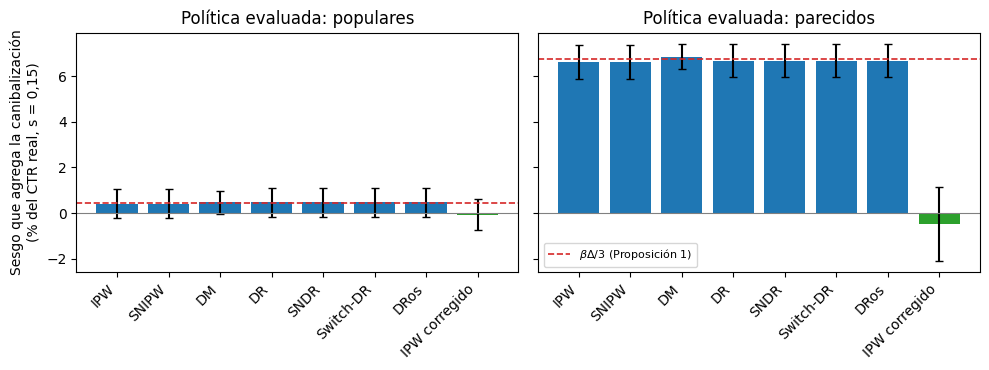

In [20]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for eje, nombre in zip(ejes, ["populares", "parecidos"]):
    t = con_canibalizacion.loc[nombre]
    colores = ["tab:green" if e == "IPW corregido" else "tab:blue" for e in t.index]
    eje.bar(range(len(t)), t["Cambio por canibalización (%)"], yerr=1.96 * t["Error estándar del cambio (%)"],
            color=colores, capsize=3)
    eje.axhline(t["beta Delta / 3 (%)"].iloc[0], color="tab:red", ls="--", lw=1.2, label=r"$\beta\Delta/3$ (Proposición 1)")
    eje.axhline(0, color="gray", lw=0.8)
    eje.set_xticks(range(len(t)))
    eje.set_xticklabels(t.index, rotation=45, ha="right")
    eje.set_title(f"Política evaluada: {nombre}")
ejes[0].set_ylabel("Sesgo que agrega la canibalización\n(% del CTR real, s = 0,15)")
ejes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig("resultados/fig_sintetico_estimadores_obp.png", dpi=200)
plt.show()

- Con *parecidos*, la canibalización le agrega a los siete estimadores casi exactamente el sesgo que predice la Proposición 1, entre 6,6 % y 6,9 % del CTR, contra 6,7 % de $\beta\Delta/3$. Da lo mismo si el estimador usa pesos (IPW, SNIPW), un modelo de clics (DM) o ambos (DR, SNDR, Switch-DR, DRos), porque ninguno ve a los vecinos, así que ninguno lo puede corregir.
- El IPW corregido es el único que no cambia (−0,5 % ± 0,8 %), porque usa $\hat\beta$ para ajustar por los vecinos.
- Con *populares*, la canibalización agrega menos de 0,5 % de sesgo en todos los estimadores, porque $\Delta$ es chico.
- Aparte de la canibalización, DM tiene un sesgo de cerca de −20 % en los dos escenarios, porque su modelo de clics subestima un CTR tan bajo. Es el mismo patrón del benchmark, donde DM es de los más sesgados. Switch-DR da lo mismo que DR y DRos casi lo mismo, porque con logs uniformes los pesos no son extremos y el ajuste de $\lambda$ no recorta nada.
- Los sesgos de cada escenario por separado tienen un error de cerca de 2,5 % (son 100 logs de unas 10.000 filas). Por eso los estimadores con pesos aparecen con cerca de +4,5 % incluso sin canibalización, donde el sesgo real es cero. Como los dos escenarios usan los mismos logs, ese ruido es el mismo en ambos y se cancela en la diferencia pareada, que es mucho más precisa.

O sea, el supuesto de que las posiciones son independientes no es un problema solo del IPW por posición, sino de todos los estimadores comparados en el proyecto. Lo que define cuánto sesgo agrega la canibalización es $\Delta$, es decir, cuánto cambia la política evaluada la composición de las vitrinas respecto a los logs.

# Parte 3. Canibalización por saturación en KuaiRand-1K

La pregunta es si un usuario ve menos un video cuando se le acaba de mostrar otro muy parecido. Esto sería canibalización por saturación, es decir, el video parecido "le quita" interés al otro.

Para responderla causalmente usamos la intervención aleatoria de KuaiRand. Según el README del dataset, cada video recomendado tiene la misma probabilidad de ser reemplazado por un video sorteado de un pool (cerca del 0,37 % de las interacciones). Como el video insertado se elige al azar, que se parezca o no a los videos que lo acompañan también es aleatorio. Entonces se puede comparar el engagement de esos videos vecinos cuando el insertado es parecido y cuando no lo es.

Se usa KuaiRand-1K ya que tiene las secuencias completas de 1.000 usuarios.

In [21]:
KUAI_PATH = Path("Contenido/Datasets/KuaiRand-1K/data")
COLS = ["user_id", "video_id", "time_ms", "is_click", "long_view", "play_time_ms", "duration_ms", "tab"]

aleatorio = pd.read_csv(KUAI_PATH / "log_random_4_22_to_5_08_1k.csv", usecols=COLS)
estandar = pd.read_csv(KUAI_PATH / "log_standard_4_22_to_5_08_1k.csv", usecols=COLS)

pd.DataFrame({"Interacciones": [len(aleatorio), len(estandar)],
              "Usuarios": [aleatorio["user_id"].nunique(), estandar["user_id"].nunique()],
              "long_view": [aleatorio["long_view"].mean(), estandar["long_view"].mean()],
              "is_click": [aleatorio["is_click"].mean(), estandar["is_click"].mean()]},
             index=["Videos insertados al azar", "Política estándar (22/4 al 8/5)"])

,Interacciones,Usuarios,long_view,is_click
Videos insertados al azar,43028,1000,0.084155,0.174119
Política estándar (22/4 al 8/5),6657061,1000,0.260986,0.377330


## Los videos llegan en lotes

Al juntar los dos logs se ve que time_ms no es el momento en que se vio cada video. Muchos videos de un mismo usuario tienen exactamente el mismo time_ms, así que time_ms corresponde al momento en que la app pidió videos, y cada pedido trae un lote (casi siempre de 6). El video aleatorio reemplaza a uno de los videos de un lote, y nunca hay más de uno aleatorio por lote.

In [22]:
# un lote = todos los videos de un usuario con el mismo time_ms
estandar["lote"] = estandar.groupby(["user_id", "time_ms"]).ngroup()
lotes = estandar[["user_id", "time_ms", "lote"]].drop_duplicates(["user_id", "time_ms"])
lotes = lotes.sort_values(["user_id", "time_ms"]).reset_index(drop=True)
lotes["lote_anterior"] = lotes.groupby("user_id")["lote"].shift(1)
lotes["lote_siguiente"] = lotes.groupby("user_id")["lote"].shift(-1)

aleatorio = aleatorio.merge(lotes, on=["user_id", "time_ms"], how="left")
tamano = estandar.groupby("lote").size()
aleatorio["Tamaño del lote (sin el insertado)"] = aleatorio["lote"].map(tamano)

print(f"Videos insertados que caen en un lote de la política estándar: {aleatorio['lote'].notna().mean():.1%}")
print(f"Lotes con más de un video insertado: {(aleatorio.groupby(['user_id', 'time_ms']).size() > 1).sum()}")
aleatorio["Tamaño del lote (sin el insertado)"].dropna().astype(int).value_counts().sort_index().head(10).to_frame("Videos insertados")

Videos insertados que caen en un lote de la política estándar: 96.5%
Lotes con más de un video insertado: 1


,Videos insertados
1,699
2,758
3,1029
4,3054
5,23236
6,7999
7,3593
8,959
9,173
10,15


El orden de los videos dentro de un lote no se conoce, porque todos tienen el mismo time_ms. Por eso los **vecinos** del video insertado son los otros videos de su lote (en la misma pestaña, tab). Esto se parece a una vitrina de OBD, que es un grupo de ítems que se muestran juntos.

Como no se sabe el orden, algunos vecinos se vieron antes del insertado y otros después. Solo los que se vieron después pueden haber perdido interés por el insertado, así que el efecto que se estima es un promedio entre "antes" y "después" y es más chico que el efecto sobre los videos que vienen después.

Además se arman dos grupos de control con los mismos videos insertados.
- **Lote anterior.** Son los videos del pedido anterior del usuario. Se vieron antes de que apareciera el insertado, así que el insertado no puede afectarlos. Si aquí sale un efecto, el diseño tiene un problema.
- **Lote siguiente.** Son los videos del pedido siguiente. Aquí podría haber saturación que dura más de un lote.

In [23]:
aleatorio = aleatorio[aleatorio["lote"].notna()].reset_index(drop=True)

# características de los videos que se necesitan (el archivo es grande, así que se lee por partes)
necesarios = set(aleatorio["video_id"])
lotes_usados = set(aleatorio["lote"]) | set(aleatorio["lote_anterior"].dropna()) | set(aleatorio["lote_siguiente"].dropna())
necesarios |= set(estandar.loc[estandar["lote"].isin(lotes_usados), "video_id"])
partes = []
for parte in pd.read_csv(KUAI_PATH / "video_features_basic_1k.csv", usecols=["video_id", "author_id", "music_id", "tag"],
                         chunksize=1_000_000):
    partes.append(parte[parte["video_id"].isin(necesarios)])
videos = pd.concat(partes).set_index("video_id")
videos["tags"] = videos["tag"].fillna("").astype(str).str.split(",").apply(lambda l: frozenset(x for x in l if x != ""))
videos["tag_principal"] = videos["tag"].fillna("-1").astype(str).str.split(",").str[0]


def armar_pares(columna_lote, nombre):
    # una fila por cada par (video insertado, vecino)
    pares = aleatorio[["user_id", "video_id", columna_lote, "tab"]].dropna()
    pares = pares.rename(columns={columna_lote: "lote", "video_id": "insertado", "tab": "tab_insertado"})
    pares = pares.merge(estandar.drop(columns=["user_id", "time_ms"]), on="lote")
    pares = pares[pares["tab"] == pares["tab_insertado"]].reset_index(drop=True)

    ins, vec = videos.reindex(pares["insertado"]), videos.reindex(pares["video_id"])
    pares["tag_vecino"] = vec["tag_principal"].to_numpy()
    pares["Mismo tag principal"] = ins["tag_principal"].to_numpy() == vec["tag_principal"].to_numpy()
    pares["Comparte algún tag"] = [isinstance(a, frozenset) and isinstance(b, frozenset) and len(a & b) > 0
                                   for a, b in zip(ins["tags"], vec["tags"])]
    pares["Mismo autor"] = ins["author_id"].to_numpy() == vec["author_id"].to_numpy()
    pares["Misma música"] = ins["music_id"].to_numpy() == vec["music_id"].to_numpy()
    # fracción del video que se vio, con tope en 5 (se puede repetir)
    pares["Fracción vista"] = (pares["play_time_ms"] / pares["duration_ms"].where(pares["duration_ms"] > 0)).clip(0, 5)
    pares["Grupo"] = nombre
    return pares[pares["Fracción vista"].notna()]


pares = pd.concat([armar_pares("lote", "Mismo lote"),
                   armar_pares("lote_anterior", "Lote anterior (control)"),
                   armar_pares("lote_siguiente", "Lote siguiente")], ignore_index=True)
SIMILITUDES = ["Mismo tag principal", "Comparte algún tag", "Mismo autor", "Misma música"]
pares.groupby("Grupo")[SIMILITUDES].mean().mul(100).round(2).assign(Pares=pares.groupby("Grupo").size())

,Mismo tag principal,Comparte algún tag,Mismo autor,Misma música,Pares
Grupo,,,,,
Lote anterior (control),5.49,5.78,0.0,0.09,200338
Lote siguiente,5.33,5.62,0.0,0.08,200107
Mismo lote,5.52,5.77,0.0,0.09,194282


La tabla muestra en qué % de los pares el insertado es parecido al vecino, con cada definición. Mismo autor y misma música casi nunca pasan, así que no sirven. Se usan las dos definiciones con tags, que son mismo tag principal (el primero de la lista) y comparte algún tag. Cerca de un 5 % de los pares son parecidos.

Que el % sea prácticamente igual en el mismo lote, el anterior y el siguiente es lo que se espera si el insertado es aleatorio.

## Estimación

Para cada par (insertado $i$, vecino $m$) se estima

$$y_{m} = \alpha_{\text{tag}(m)} - \beta \cdot S_{im} + \varepsilon_{im},$$

donde $y_m$ es el engagement del vecino (long_view, is_click o fracción vista), $S_{im} = 1$ si el insertado es parecido al vecino y $\beta$ es la caída por canibalización (positivo = canibalización, igual que en OBD).

El efecto fijo por el tag principal del vecino es necesario, dado que un vecino con un tag común en el pool tiene más probabilidad de que le toque un insertado parecido (hay más elementos que le "sirven"), y además los videos de distintos tags tienen distinto engagement. Dentro de un mismo tag, que el insertado sea parecido es puro azar. Como chequeo, se agrega también un efecto fijo por lote, que compara vecinos del mismo lote (mismo usuario, mismo momento). Los errores estándar se agrupan por usuario.

In [24]:
def restar_promedios(x, grupos, iteraciones=20):
    # le resta a x su promedio dentro de cada grupo, y con dos tipos de grupos se repite hasta que converge
    x = x.astype(float).copy()
    for _ in range(iteraciones if len(grupos) > 1 else 1):
        for g in grupos:
            x = x - (np.bincount(g, x) / np.bincount(g))[g]
    return x


def estimar_beta_kuai(df, y, similitud, efectos_fijos):
    grupos = [pd.factorize(df[f])[0] for f in efectos_fijos]
    y_dm = restar_promedios(df[y].to_numpy(), grupos)
    s_dm = restar_promedios(df[similitud].to_numpy().astype(float), grupos)
    pendiente = (s_dm * y_dm).sum() / (s_dm ** 2).sum()

    # error estándar agrupado por usuario
    residuo = y_dm - pendiente * s_dm
    aporte = np.bincount(pd.factorize(df["user_id"])[0], s_dm * residuo)
    se = np.sqrt((aporte ** 2).sum()) / (s_dm ** 2).sum()
    return -pendiente, se      # beta es la caída, por eso cambio el signo


RESULTADOS = ["long_view", "is_click", "Fracción vista"]
EFECTOS = {"tag del vecino": ["tag_vecino"], "tag del vecino + lote": ["tag_vecino", "lote"]}

filas = []
for grupo, df in pares.groupby("Grupo"):
    for y in RESULTADOS:
        for similitud in ["Mismo tag principal", "Comparte algún tag"]:
            for nombre_ef, ef in EFECTOS.items():
                g, se = estimar_beta_kuai(df, y, similitud, ef)
                base = df[y].mean()
                filas.append({"Grupo": grupo, "Resultado": y, "Similitud": similitud, "Efectos fijos": nombre_ef,
                              "beta": g, "Error estándar": se, "z": g / se, "Promedio": base,
                              "beta / promedio (%)": g / base * 100,
                              "IC 95% (%)": f"[{(g - 1.96 * se) / base * 100:.1f}, {(g + 1.96 * se) / base * 100:.1f}]",
                              "Efecto mínimo detectable (%)": 2.8 * se / base * 100,
                              "Pares": len(df), "Pares parecidos": int(df[similitud].sum())})

saturacion = pd.DataFrame(filas).set_index(["Grupo", "Resultado", "Similitud", "Efectos fijos"])
saturacion.loc["Mismo lote"].round(4)

beta  \
Resultado      Similitud           Efectos fijos                   
long_view      Mismo tag principal tag del vecino        -0.0008   
                                   tag del vecino + lote -0.0037   
               Comparte algún tag  tag del vecino         0.0034   
                                   tag del vecino + lote -0.0019   
is_click       Mismo tag principal tag del vecino         0.0053   
                                   tag del vecino + lote  0.0052   
               Comparte algún tag  tag del vecino         0.0078   
                                   tag del vecino + lote  0.0055   
Fracción vista Mismo tag principal tag del vecino         0.0042   
                                   tag del vecino + lote -0.0039   
               Comparte algún tag  tag del vecino         0.0098   
                                   tag del vecino + lote -0.0008   

                                                          Error estándar  \
Resultado      Similitud           Efectos fijos                           
long_view      Mismo tag principal tag del vecino                 0.0053   
                                   tag del vecino + lote          0.0059   
               Comparte algún tag  tag del vecino                 0.0051   
                                   tag del vecino + lote          0.0057   
is_click       Mismo tag principal tag del vecino                 0.0053   
                                   tag del vecino + lote          0.0056   
               Comparte algún tag  tag del vecino                 0.0051   
                                   tag del vecino + lote          0.0054   
Fracción vista Mismo tag principal tag del vecino                 0.0066   
                                   tag del vecino + lote          0.0073   
               Comparte algún tag  tag del vecino                 0.0063   
                                   tag del vecino + lote          0.0071   

                                                               z  Promedio  \
Resultado      Similitud           Efectos fijos                             
long_view      Mismo tag principal tag del vecino        -0.1428    0.3837   
                                   tag del vecino + lote -0.6313    0.3837   
               Comparte algún tag  tag del vecino         0.6538    0.3837   
                                   tag del vecino + lote -0.3391    0.3837   
is_click       Mismo tag principal tag del vecino         1.0001    0.5113   
                                   tag del vecino + lote  0.9345    0.5113   
               Comparte algún tag  tag del vecino         1.5222    0.5113   
                                   tag del vecino + lote  1.0236    0.5113   
Fracción vista Mismo tag principal tag del vecino         0.6443    0.5531   
                                   tag del vecino + lote -0.5369    0.5531   
               Comparte algún tag  tag del vecino         1.5558    0.5531   
                                   tag del vecino + lote -0.1102    0.5531   

                                                          beta / promedio (%)  \
Resultado      Similitud           Efectos fijos                                
long_view      Mismo tag principal tag del vecino                     -0.1988   
                                   tag del vecino + lote              -0.9627   
               Comparte algún tag  tag del vecino                      0.8756   
                                   tag del vecino + lote              -0.4995   
is_click       Mismo tag principal tag del vecino                      1.0441   
                                   tag del vecino + lote               1.0162   
               Comparte algún tag  tag del vecino                      1.5296   
                                   tag del vecino + lote               1.0853   
Fracción vista Mismo tag principal tag del vecino                      0.7631   
                                   tag del vecino + lote  

Con cualquier resultado y cualquier definición de similitud, $\beta$ es muy cercano a cero y ningún efecto es significativo ($|z| < 1{,}6$). A diferencia de OBD, aquí la estimación es precisa, dado que con 194 mil pares y 11 mil parecidos, se puede descartar una caída mayor a 4 % del promedio con cualquier resultado (el extremo superior de los intervalos de confianza llega como máximo a 4 %, y en long_view a 3,5 %). O sea, que un vecino del lote se parezca al video insertado no le baja el engagement de forma apreciable.

In [25]:
# los dos grupos de control, solo con efecto fijo por tag del vecino
(saturacion.xs("tag del vecino", level="Efectos fijos")
 .loc[["Lote anterior (control)", "Lote siguiente"], ["beta", "Error estándar", "z", "beta / promedio (%)", "IC 95% (%)"]]
 .round(4))

beta  \
Grupo                   Resultado      Similitud                     
Lote anterior (control) long_view      Mismo tag principal -0.0041   
                                       Comparte algún tag  -0.0019   
                        is_click       Mismo tag principal  0.0029   
                                       Comparte algún tag   0.0040   
                        Fracción vista Mismo tag principal -0.0017   
                                       Comparte algún tag   0.0029   
Lote siguiente          long_view      Mismo tag principal -0.0043   
                                       Comparte algún tag  -0.0027   
                        is_click       Mismo tag principal -0.0077   
                                       Comparte algún tag  -0.0057   
                        Fracción vista Mismo tag principal  0.0056   
                                       Comparte algún tag   0.0083   

                                                            Error estándar  \
Grupo                   Resultado      Similitud                             
Lote anterior (control) long_view      Mismo tag principal          0.0050   
                                       Comparte algún tag           0.0049   
                        is_click       Mismo tag principal          0.0050   
                                       Comparte algún tag           0.0049   
                        Fracción vista Mismo tag principal          0.0060   
                                       Comparte algún tag           0.0059   
Lote siguiente          long_view      Mismo tag principal          0.0049   
                                       Comparte algún tag           0.0048   
                        is_click       Mismo tag principal          0.0051   
                                       Comparte algún tag           0.0050   
                        Fracción vista Mismo tag principal          0.0062   
                                       Comparte algún tag           0.0061   

                                                                 z  \
Grupo                   Resultado      Similitud                     
Lote anterior (control) long_view      Mismo tag principal -0.8301   
                                       Comparte algún tag  -0.3887   
                        is_click       Mismo tag principal  0.5806   
                                       Comparte algún tag   0.8081   
                        Fracción vista Mismo tag principal -0.2773   
                                       Comparte algún tag   0.4994   
Lote siguiente          long_view      Mismo tag principal -0.8635   
                                       Comparte algún tag  -0.5558   
                        is_click       Mismo tag principal -1.4961   
                                       Comparte algún tag  -1.1352   
                        Fracción vista Mismo tag principal  0.9034   
                                       Comparte algún tag   1.3684   

                                                            beta / promedio (%)  \
Grupo                   Resultado      Similitud                                  
Lote anterior (control) long_view      Mismo tag principal              -1.0921   
                                       Comparte algún tag               -0.4993   
                        is_click       Mismo tag principal               0.5760   
                                       Comparte algún tag                0.7843   
                        Fracción vista Mismo tag principal              -0.3031   
                                       Comparte algún tag                0.5347   
Lote siguiente          long_view      Mismo tag principal              -1.1313   
                                       Comparte algún tag               -0.7097   
                        is_click       Mismo tag principal              -1.5158   
                                       Comparte algún tag               -1.1177   
           

En el lote anterior, que no puede haber sido afectado por el insertado, tampoco hay efecto, así que no hay señales de que el diseño esté sesgado. En el lote siguiente tampoco aparece saturación que dure más allá del lote.

## Forma multiplicativa

El modelo lineal supone que un insertado parecido le quita la misma cantidad de engagement a cualquier vecino. En la forma multiplicativa le quita una fracción, según

$$P(y_m = 1) = \theta_m \cdot e^{-\gamma S_{im}},$$

así que cada insertado parecido le quita un $1 - e^{-\gamma}$ del engagement al vecino, y los videos con más engagement pierden más en términos absolutos. En OBD las dos formas eran casi iguales porque el CTR era 0,5 %, pero aquí long_view está cerca de 38 %, así que predicen cosas distintas.

Lo ideal sería un $\theta$ por video, pero la mayoría de los videos aparece muy pocas veces en el log, así que $\theta$ se define por celda, combinando el tag principal del vecino con su quintil de popularidad. Como popularidad se usa show_cnt de video_features_statistic_1k.csv, que es el promedio diario de veces que se mostró el video en toda la app durante un mes. Así la popularidad no sale de los mismos 1.000 usuarios.

In [26]:
vecinos_ids = set(pares["video_id"])
partes = []
for parte in pd.read_csv(KUAI_PATH / "video_features_statistic_1k.csv", usecols=["video_id", "show_cnt"],
                         chunksize=500_000):
    partes.append(parte[parte["video_id"].isin(vecinos_ids)])
popularidad = pd.concat(partes).drop_duplicates("video_id").set_index("video_id")["show_cnt"]

pares["Popularidad"] = pares["video_id"].map(popularidad)
pares["Quintil de popularidad"] = pd.qcut(pares["Popularidad"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5])
pares["Celda"] = pares["tag_vecino"].astype(str) + "_" + pares["Quintil de popularidad"].astype(str)

mismo_lote = pares[pares["Grupo"] == "Mismo lote"]
print(f"Vecinos sin popularidad: {pares['Popularidad'].isna().mean():.2%}")
mismo_lote.groupby("Quintil de popularidad").agg(
    **{"Pares": ("long_view", "size"), "show_cnt mediano": ("Popularidad", "median"), "long_view": ("long_view", "mean"),
       "% pares parecidos": ("Mismo tag principal", "mean")}).round(3)

Vecinos sin popularidad: 0.00%


,Pares,show_cnt mediano,long_view,% pares parecidos
Quintil de popularidad,,,,
1,38993,1215.714,0.275,0.041
2,39014,6918.843,0.351,0.051
3,38656,21334.229,0.396,0.058
4,38421,55351.722,0.434,0.063
5,39198,188958.757,0.463,0.063


Los videos más populares tienen más engagement. Además, tienen un poco más de probabilidad de que el insertado sea parecido a ellos, así que la popularidad también sirve de control.

Para estimar $\gamma$ se usa la misma regresión de Poisson con efectos fijos que en OBD, pero con las celdas tag × quintil en vez de ítem × posición. Aunque long_view es binario, Poisson igual estima bien $\gamma$ si la forma multiplicativa es correcta. El error estándar se agrupa por usuario. Para comparar, se estima también el $\beta$ lineal con los mismos efectos fijos.

In [27]:
def estimar_gamma_kuai(df, y, similitud, celdas="Celda"):
    celda = pd.factorize(df[celdas])[0]
    n_celdas = celda.max() + 1
    r, c = df[y].to_numpy().astype(float), df[similitud].to_numpy().astype(float)
    total_celda = np.bincount(celda, r, n_celdas)

    def esperado(gamma):
        e = np.exp(-gamma * c)
        return (total_celda / np.maximum(np.bincount(celda, e, n_celdas), 1e-300))[celda] * e

    def derivada(gamma):
        return (c * (r - esperado(gamma))).sum()

    gamma = brentq(derivada, -3, 3)

    # error estándar agrupado por usuario
    mu = esperado(gamma)
    c_prom = (np.bincount(celda, mu * c, n_celdas) / np.maximum(np.bincount(celda, mu, n_celdas), 1e-300))[celda]
    curvatura = (mu * (c - c_prom) ** 2).sum()
    aporte = np.bincount(pd.factorize(df["user_id"])[0], (r - mu) * (c - c_prom))
    return gamma, np.sqrt((aporte ** 2).sum()) / curvatura


filas = []
for y in RESULTADOS:
    for similitud in ["Mismo tag principal", "Comparte algún tag"]:
        g, se_g = estimar_gamma_kuai(mismo_lote, y, similitud)
        b, se_b = estimar_beta_kuai(mismo_lote, y, similitud, ["Celda"])
        base = mismo_lote[y].mean()
        filas.append({"Resultado": y, "Similitud": similitud, "gamma": g, "Error estándar": se_g, "z": g / se_g,
                      "Pérdida multiplicativa 1 - e^-gamma (%)": (1 - np.exp(-g)) * 100,
                      "IC 95% (%)": f"[{(1 - np.exp(-(g - 1.96 * se_g))) * 100:.1f}, {(1 - np.exp(-(g + 1.96 * se_g))) * 100:.1f}]",
                      "Pérdida lineal beta / promedio (%)": b / base * 100})

multiplicativo = pd.DataFrame(filas).set_index(["Resultado", "Similitud"])
multiplicativo.round(4)

gamma  Error estándar       z  \
Resultado      Similitud                                             
long_view      Mismo tag principal -0.0008          0.0127 -0.0625   
               Comparte algún tag   0.0081          0.0124  0.6561   
is_click       Mismo tag principal  0.0100          0.0096  1.0452   
               Comparte algún tag   0.0139          0.0093  1.4933   
Fracción vista Mismo tag principal  0.0090          0.0139  0.6433   
               Comparte algún tag   0.0202          0.0136  1.4864   

                                    Pérdida multiplicativa 1 - e^-gamma (%)  \
Resultado      Similitud                                                      
long_view      Mismo tag principal                                  -0.0792   
               Comparte algún tag                                    0.8104   
is_click       Mismo tag principal                                   0.9967   
               Comparte algún tag                                    1.3826   
Fracción vista Mismo tag principal                                   0.8918   
               Comparte algún tag                                    2.0017   

                                     IC 95% (%)  \
Resultado      Similitud                          
long_view      Mismo tag principal  [-2.6, 2.4]   
               Comparte algún tag   [-1.6, 3.2]   
is_click       Mismo tag principal  [-0.9, 2.8]   
               Comparte algún tag   [-0.4, 3.2]   
Fracción vista Mismo tag principal  [-1.9, 3.6]   
               Comparte algún tag   [-0.6, 4.6]   

                                    Pérdida lineal beta / promedio (%)  
Resultado      Similitud                                                
long_view      Mismo tag principal                             -0.0867  
               Comparte algún tag                               0.8833  
is_click       Mismo tag principal                              1.0938  
               Comparte algún tag                               1.5102  
Fracción vista Mismo tag principal                              0.7626  
               Comparte algún tag                               1.7142

### Comparación de formas

Como el engagement cambia bastante entre quintiles de popularidad, se puede comparar qué predice cada forma. Si la forma es lineal, la caída absoluta ($\beta$) debería ser igual en todos los quintiles. Si es multiplicativa, la caída relativa ($\beta$ / promedio) debería ser igual, y la absoluta debería crecer con la popularidad. Se estima $\beta$ por separado en cada quintil, para long_view y mismo tag principal.

In [28]:
filas = []
for q, df in mismo_lote.groupby("Quintil de popularidad"):
    b, se_b = estimar_beta_kuai(df, "long_view", "Mismo tag principal", ["tag_vecino"])
    base = df["long_view"].mean()
    filas.append({"Quintil de popularidad": q, "long_view promedio": base, "beta (caída absoluta)": b,
                  "Error estándar": se_b, "beta / promedio (%)": b / base * 100,
                  "IC 95% de beta / promedio (%)": f"[{(b - 1.96 * se_b) / base * 100:.1f}, {(b + 1.96 * se_b) / base * 100:.1f}]"})
pd.DataFrame(filas).set_index("Quintil de popularidad").round(4)

,long_view promedio,beta (caída absoluta),Error estándar,beta / promedio (%),IC 95% de beta / promedio (%)
Quintil de popularidad,,,,,
1,0.2749,0.0123,0.0122,4.4601,"[-4.3, 13.2]"
2,0.3510,-0.0107,0.0119,-3.0526,"[-9.7, 3.6]"
3,0.3962,-0.0036,0.0111,-0.8988,"[-6.4, 4.6]"
4,0.4341,-0.0110,0.0108,-2.5248,"[-7.4, 2.4]"
5,0.4630,0.0130,0.0115,2.8159,"[-2.0, 7.7]"


- $\gamma$ también es prácticamente cero con cualquier resultado y definición de similitud. La pérdida multiplicativa va de −0,1 % a 2,0 % y ninguna es significativa ($|z| < 1{,}5$). Con los intervalos se puede descartar que un insertado parecido le quite más de 2,4 % del long_view a su vecino (mismo tag principal), y más de 4,6 % con cualquier resultado.
- Las dos formas dan prácticamente lo mismo cuando se expresan en % del promedio.
- Por quintil de popularidad, las caídas van de −3 % a 4,5 % sin ningún patrón y con intervalos que se traslapan. Ni la caída absoluta ni la relativa cambian de forma sistemática con la popularidad. Como el efecto es casi cero en todos los quintiles, estos datos no permiten distinguir entre las dos formas, y ambas son compatibles con lo observado.

**Conclusión.** En KuaiRand no se detecta canibalización por saturación entre videos de un mismo lote, ni con la forma lineal ni con la multiplicativa. Si existe, es menor a cerca de 5 % del engagement. Esto calza con lo que se encontró en OBD, pero con mucha más precisión. Hay que tener en cuenta tres limitaciones. Como no se conoce el orden dentro del lote, el efecto sobre los videos que vienen después del insertado podría ser hasta el doble del estimado. Además, la similitud se define solo con los tags, y en la forma multiplicativa el engagement base se aproxima por celdas de tag y popularidad, no por video.

# Figura de estimaciones de beta

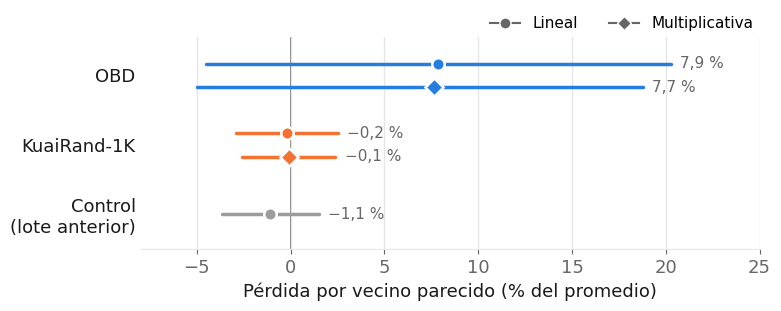

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

AZUL, NARANJA, GRIS = "#257de0", "#f47230", "#9c9c9c"
TXT, TXT2, GRID = "#191919", "#666666", "#e6e6e6"


def lineal_pct(b, se, base):
    # pérdida lineal como % del promedio, con su IC 95%
    return b / base * 100, (b - 1.96 * se) / base * 100, (b + 1.96 * se) / base * 100


def multiplicativa_pct(g, se):
    # pérdida multiplicativa 1 - e^-gamma, con el IC 95% transformado desde gamma
    return (1 - np.exp(-g)) * 100, (1 - np.exp(-(g - 1.96 * se))) * 100, (1 - np.exp(-(g + 1.96 * se))) * 100


obd = comparacion.loc[CAMPAIGN]
kr = saturacion.xs("tag del vecino", level="Efectos fijos")
kr_mismo = kr.loc[("Mismo lote", "long_view", "Mismo tag principal")]
kr_control = kr.loc[("Lote anterior (control)", "long_view", "Mismo tag principal")]
kr_mult = multiplicativo.loc[("long_view", "Mismo tag principal")]

# una fila por dataset, y en cada fila la forma lineal (arriba) y la multiplicativa (abajo)
grupos_fig4 = [
    ("OBD", AZUL, [lineal_pct(obd["beta"], obd["Error estándar"], obd["CTR"]),
                   multiplicativa_pct(gamma, se_gamma)]),
    ("KuaiRand-1K", NARANJA, [lineal_pct(kr_mismo["beta"], kr_mismo["Error estándar"], kr_mismo["Promedio"]),
                              multiplicativa_pct(kr_mult["gamma"], kr_mult["Error estándar"])]),
    ("Control\n(lote anterior)", GRIS, [lineal_pct(kr_control["beta"], kr_control["Error estándar"],
                                                   kr_control["Promedio"])]),
]
MARCAS = ["o", "D"]
DESPLAZAMIENTO = [0.17, -0.17]

plt.rcParams.update({"font.size": 13, "axes.edgecolor": GRID, "axes.labelcolor": TXT, "xtick.color": TXT2,
                     "ytick.color": TXT, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 3.3))
for k, (nombre, color, formas) in enumerate(grupos_fig4):
    y0 = len(grupos_fig4) - 1 - k
    if len(formas) == 1:
        desplazamientos = [0]
    else:
        desplazamientos = DESPLAZAMIENTO
    for (v, lo, hi), marca, d in zip(formas, MARCAS, desplazamientos):
        ax.plot([lo, hi], [y0 + d] * 2, color=color, lw=2.5, solid_capstyle="round")
        ax.plot(v, y0 + d, marca, ms=9, color=color, mec="white", mew=1.8, zorder=3)
        ax.text(hi + 0.5, y0 + d, f"{v:.1f} %".replace(".", ",").replace("-", "−"), va="center", fontsize=11, color=TXT2)
ax.axvline(0, color=TXT2, lw=1.2, zorder=0)
ax.set_yticks(range(len(grupos_fig4)))
ax.set_yticklabels([g[0] for g in grupos_fig4][::-1])
ax.set_ylim(-0.5, len(grupos_fig4) - 0.45)
ax.set_xlim(-8, 25)
ax.set_xlabel("Pérdida por vecino parecido (% del promedio)")
ax.grid(axis="x", color=GRID, lw=1)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
leyenda = [Line2D([], [], marker="o", ls="-", color=TXT2, mec="white", ms=8, label="Lineal"),
           Line2D([], [], marker="D", ls="-", color=TXT2, mec="white", ms=7, label="Multiplicativa")]
ax.legend(handles=leyenda, loc="lower right", frameon=False, fontsize=11, ncol=2,
          bbox_to_anchor=(1, 1), borderaxespad=0)
fig.tight_layout()
os.makedirs("resultados/poster", exist_ok=True)
fig.savefig("resultados/poster/fig4_beta.png", dpi=300)
fig.savefig("resultados/poster/fig4_beta.pdf")
plt.show()
plt.rcdefaults() 

# Resumen

- **OBD.** Un vecino de la misma categoría le quitaría cerca de 8 % del CTR al ítem (7,9 % con la forma lineal y 7,7 % con la multiplicativa), pero no es significativo. Con estos datos solo se detectarían efectos mayores a cerca de 18 % del CTR. La canibalización explica entre 0,4 % y 1,3 % del sesgo de los estimadores en el benchmark de Saito et al., y en dirección contraria (DR queda fuera de ese rango porque su sesgo total no es significativo).
- **Sintético.** El sesgo del IPW por posición es exactamente $\beta\Delta/3$. Solo importa cuando la política evaluada junta muchos más ítems parecidos que los logs (como *parecidos*), y aun así el IPW de vitrina recién conviene con al menos 700 mil vitrinas, es decir, 2,1 millones de filas (con logs uniformes y estas políticas). Los siete estimadores del benchmark (IPW, SNIPW, DM, DR, SNDR, Switch-DR y DRos) heredan ese mismo sesgo, porque ninguno ve a los vecinos. Solo el IPW por posición corregido con $\hat\beta$ lo elimina, y sirve sobre todo con muestras grandes.
- **KuaiRand-1K.** Con un diseño aleatorio más limpio y más datos, la canibalización por saturación es prácticamente cero, con las dos formas. Se pueden descartar caídas mayores a cerca de 4–5 % del engagement.

En conjunto, el supuesto del IPW por posición de que el clic en un ítem no depende de sus vecinos se cumple bastante bien en los dos datasets reales, para esta noción de similitud.

**Declaración de uso de IA**

Utilicé IA para que se entienda de forma correcta lo que hace cada parte del código y la construcción teórica matemática de cada segmento (markdowns) y para tratar inicialmente los datos (recuperar la información relevante al momento de cargar los datos). Además, se utilizó como apoyo en el código, tanto para crear el código del dataset sintético, hacer figuras, y para arreglar errores y hacer ajustes.